
# <font color="#0056B3">People Analytics & Workforce Insights</font>



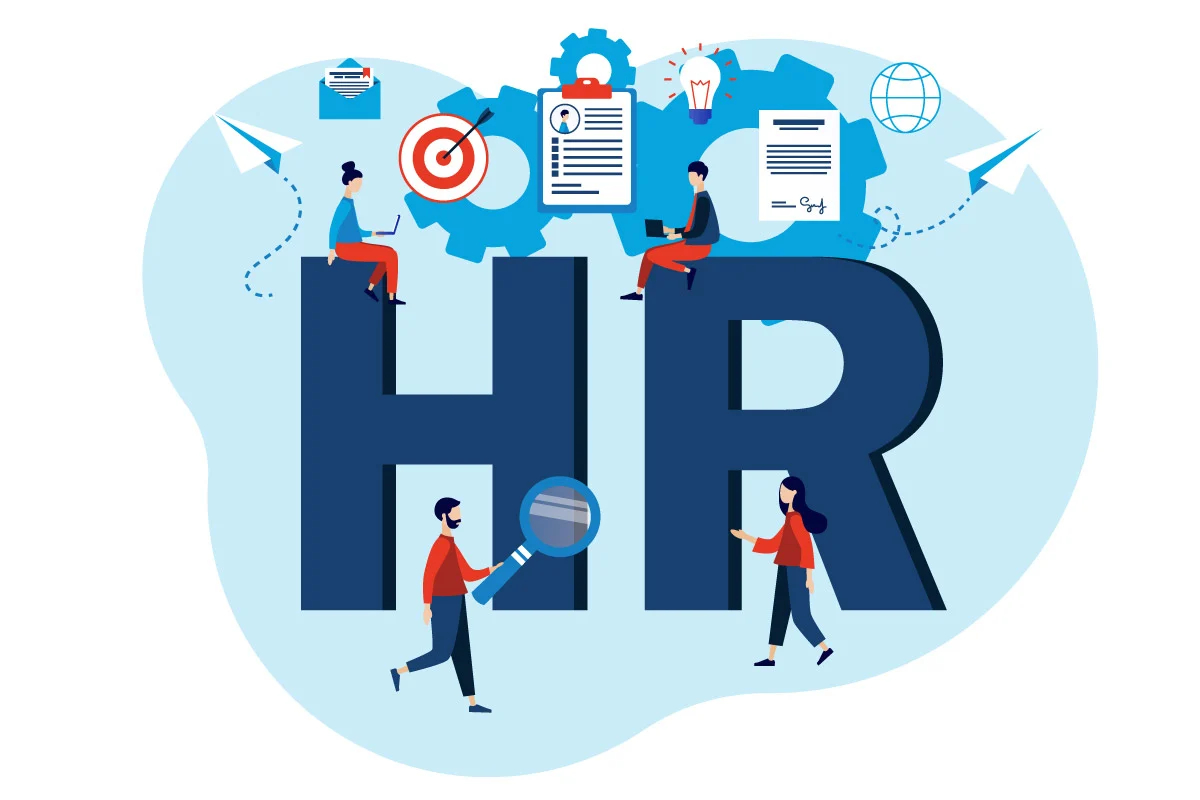

The five phases are:

- Ask an interesting question





- Get the data
- Explore the data
- Model the data
- Communicate and visualize the results

--------------------------------------------------------------------------------------------------------------------------------


# 1. Problem Understanding & Business Objectives



## 1.1 Business Problem

Employee turnover can increase hiring costs and affect team performance.

This project uses employee data to understand why employees may leave a company and to identify patterns linked to employee turnover.



## 1.2 Project Objectives

- Understand employee data.
- Analyze employee turnover.
- Find patterns linked to employees leaving.
- Build a machine learning model to predict employee turnover.
- Support HR decisions with data.



## 1.3 Business Questions

1. How many employees left the company?
2. What is the employee turnover rate?
3. Is employee satisfaction linked to turnover?
4. Are working hours linked to turnover?
5. Does salary level relate to turnover?
6. Which departments have higher turnover?
7. Can we predict employee turnover using machine learning?



## 2.1 Data Source & Description

**Dataset Name:** HR Analytics Dataset

**Source:** Kaggle

**Dataset Link:** https://www.kaggle.com/datasets/ayoreynolds/hr-capstone-dataset

**Description:**

This dataset contains 14,999 employee records and 10 columns.

It includes employee satisfaction, performance evaluation, projects, working hours, years at the company, work accidents, promotions, department, salary, and employee turnover.

**Target Variable:** `left`

This column shows whether an employee left the company.

**Project Goal:**

Analyze employee data to identify patterns linked to employee turnover and build a machine learning model to predict it.



# 3. Data Understanding & Initial Exploration


In [2]:

import pandas as pd
from IPython.display import display, HTML

# ==========================================
# 3.1 Read Dataset
# ==========================================

display(HTML("""
<h2 style="font-size:26px; color:#0056B3;">
3.1 Read Dataset
</h2>
"""))

file_path = "/content/HR_capstone_dataset.csv"

try:
    df = pd.read_csv(file_path)

    print("Dataset loaded successfully!")
    print(f"Number of Rows: {df.shape[0]:,}")
    print(f"Number of Columns: {df.shape[1]:,}")

except FileNotFoundError:
    print("File not found. Please check the file path.")
    raise

# ==========================================
# 3.2 Check Dataset
# ==========================================

display(HTML("""
<h2 style="font-size:26px; color:#0056B3;">
3.2 Check Dataset
</h2>
"""))

# 1. Preview the data
display(HTML("<h3>1. Data Preview</h3>"))
display(df.head())

# 2. Dataset structure
display(HTML("<h3>2. Dataset Information</h3>"))
print("Dataset Shape:", df.shape)
df.info()

# 3. Column names and data types
display(HTML("<h3>3. Column Names and Data Types</h3>"))
column_info = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Values": df.notna().sum().values,
    "Unique Values": df.nunique().values
})
display(column_info)

# 4. Missing values
display(HTML("<h3>4. Missing Values</h3>"))
missing_info = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (
        df.isnull().mean() * 100
    ).round(2)
})
display(missing_info)

# 5. Duplicate rows
display(HTML("<h3>5. Duplicate Rows</h3>"))
duplicate_count = df.duplicated().sum()
print(f"Number of Duplicate Rows: {duplicate_count:,}")

# 6. Numerical summary
display(HTML("<h3>6. Numerical Summary</h3>"))
display(df.describe().T.round(2))

# 7. Categorical summary
display(HTML("<h3>7. Categorical Summary</h3>"))
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

if len(categorical_columns) > 0:
    display(df[categorical_columns].describe().T)
else:
    print("No categorical columns found.")

# 8. Target variable check
if "left" in df.columns:
    display(HTML("<h3>8. Employee Attrition Distribution</h3>"))

    attrition_summary = pd.DataFrame({
        "Employee Count": df["left"].value_counts(),
        "Percentage (%)": (
            df["left"].value_counts(normalize=True) * 100
        ).round(2)
    })

    display(attrition_summary.sort_index())

# 9. Initial data quality summary
display(HTML("<h3>9. Initial Data Quality Summary</h3>"))

print(f"Total Records: {len(df):,}")
print(f"Total Columns: {df.shape[1]:,}")
print(f"Missing Values: {df.isnull().sum().sum():,}")
print(f"Duplicate Rows: {duplicate_count:,}")

print("\nDataset inspection completed.")


Dataset loaded successfully!
Number of Rows: 14,999
Number of Columns: 10


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


Dataset Shape: (14999, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


,Column Name,Data Type,Non-Null Values,Unique Values
0,satisfaction_level,float64,14999,92
1,last_evaluation,float64,14999,65
2,number_project,int64,14999,6
3,average_montly_hours,int64,14999,215
4,time_spend_company,int64,14999,8
5,Work_accident,int64,14999,2
6,left,int64,14999,2
7,promotion_last_5years,int64,14999,2
8,Department,object,14999,10
9,salary,object,14999,3


,Missing Count,Missing Percentage (%)
satisfaction_level,0,0.0
last_evaluation,0,0.0
number_project,0,0.0
average_montly_hours,0,0.0
time_spend_company,0,0.0
Work_accident,0,0.0
left,0,0.0
promotion_last_5years,0,0.0
Department,0,0.0
salary,0,0.0


Number of Duplicate Rows: 3,008


,count,mean,std,min,25%,50%,75%,max
satisfaction_level,14999.0,0.61,0.25,0.09,0.44,0.64,0.82,1.0
last_evaluation,14999.0,0.72,0.17,0.36,0.56,0.72,0.87,1.0
number_project,14999.0,3.80,1.23,2.00,3.00,4.00,5.00,7.0
average_montly_hours,14999.0,201.05,49.94,96.00,156.00,200.00,245.00,310.0
time_spend_company,14999.0,3.50,1.46,2.00,3.00,3.00,4.00,10.0
Work_accident,14999.0,0.14,0.35,0.00,0.00,0.00,0.00,1.0
left,14999.0,0.24,0.43,0.00,0.00,0.00,0.00,1.0
promotion_last_5years,14999.0,0.02,0.14,0.00,0.00,0.00,0.00,1.0


,count,unique,top,freq
Department,14999,10,sales,4140
salary,14999,3,low,7316


,Employee Count,Percentage (%)
left,,
0,11428,76.19
1,3571,23.81


Total Records: 14,999
Total Columns: 10
Missing Values: 0
Duplicate Rows: 3,008

Dataset inspection completed.


In [3]:

import pandas as pd
from IPython.display import display, HTML

# Target variable
target = "left"

# Display title
display(HTML("""
<h3 style="color:#0056B3; font-size:22px;">
Target Variable: Employee Attrition
</h3>
"""))

# Explain target values
target_mapping = pd.DataFrame({
    "Value": [0, 1],
    "Meaning": [
        "Employee stayed",
        "Employee left"
    ],
    "Description": [
        "The employee did not leave the company",
        "The employee left the company"
    ]
})

display(target_mapping)

# Count and percentage
target_summary = (
    df[target]
    .value_counts()
    .sort_index()
    .rename(index={0: "Stayed (0)", 1: "Left (1)"})
    .to_frame("Employee Count")
)

target_summary["Percentage (%)"] = (
    target_summary["Employee Count"] / len(df) * 100
).round(2)

display(target_summary)

# Validate target values
print("Unique target values:", sorted(df[target].dropna().unique()))
print("Missing target values:", df[target].isna().sum())


,Value,Meaning,Description
0,0,Employee stayed,The employee did not leave the company
1,1,Employee left,The employee left the company


,Employee Count,Percentage (%)
left,,
Stayed (0),11428,76.19
Left (1),3571,23.81


Unique target values: [np.int64(0), np.int64(1)]
Missing target values: 0


**Workforce Challenges & Business Problem Classification**

**تصنيف تحديات القوى العاملة وتحليل الوضع الراهن في بيئات الأعمال**

تحديد وتصنيف المشكلات الفعلية التي تواجه بيئات العمل في إدارة الموارد البشرية، وتحليل الوضع الراهن للقوى العاملة بهدف متابعة مؤشرات الأداء والاستقرار الوظيفي، وفهم العوامل المرتبطة بمغادرة الموظفين، ودعم جهود الاحتفاظ بالكفاءات وتحسين بيئة العمل من خلال تحليل البيانات.


,Column Name,Data Type,Non-Null Count,Missing Count,Unique Values
0,satisfaction_level,float64,14999,0,92
1,last_evaluation,float64,14999,0,65
2,number_project,int64,14999,0,6
3,average_montly_hours,int64,14999,0,215
4,time_spend_company,int64,14999,0,8
5,Work_accident,int64,14999,0,2
6,left,int64,14999,0,2
7,promotion_last_5years,int64,14999,0,2
8,Department,object,14999,0,10
9,salary,object,14999,0,3


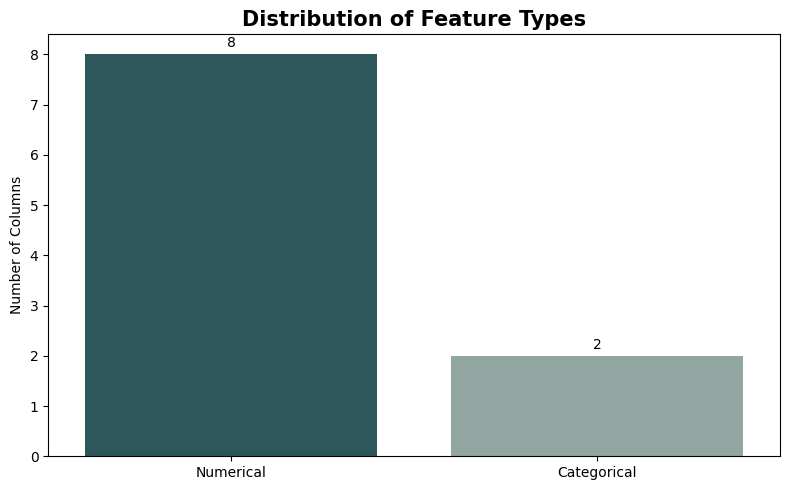

Target Variable Identified: left


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

# ==========================================
# 1. Read Dataset
# ==========================================

file_path = "/content/HR_capstone_dataset.csv"
df = pd.read_csv(file_path)

# ==========================================
# 2. Dataset Overview
# ==========================================

total_rows = df.shape[0]
total_columns = df.shape[1]

numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

total_numerical = len(numerical_columns)
total_categorical = len(categorical_columns)

missing_values = df.isnull().sum().sum()
duplicate_rows = df.duplicated().sum()

# ==========================================
# 3. Professional Overview Cards
# ==========================================

display(HTML("""
<h2 style="color:#275D62; font-size:26px;">
Dataset Overview
</h2>
<p style="color:gray;">
Initial inspection of the HR dataset
</p>
"""))

metrics = [
    ("Total Rows", f"{total_rows:,}"),
    ("Total Columns", f"{total_columns:,}"),
    ("Numerical Features", f"{total_numerical:,}"),
    ("Categorical Features", f"{total_categorical:,}"),
    ("Missing Values", f"{missing_values:,}"),
    ("Duplicate Rows", f"{duplicate_rows:,}")
]

cards_html = """
<div style="
display:grid;
grid-template-columns:repeat(3,1fr);
gap:12px;
font-family:Arial;
">
"""

for label, value in metrics:
    cards_html += f"""
    <div style="
    background:#F3F7F6;
    padding:20px;
    border-radius:12px;
    border-left:4px solid #275D62;
    ">
        <div style="color:#64748B;font-size:13px;">
        {label}
        </div>
        <div style="
        color:#172C3A;
        font-size:27px;
        font-weight:bold;
        margin-top:8px;
        ">
        {value}
        </div>
    </div>
    """

cards_html += "</div>"

display(HTML(cards_html))

# ==========================================
# 4. Column Information Table
# ==========================================

column_info = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Missing Count": df.isnull().sum().values,
    "Unique Values": df.nunique().values
})

display(HTML("""
<h3 style="color:#275D62;">
Column Information
</h3>
"""))

display(column_info)

# ==========================================
# 5. Feature Types Visualization
# ==========================================

feature_summary = pd.DataFrame({
    "Feature Type": ["Numerical", "Categorical"],
    "Count": [total_numerical, total_categorical]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=feature_summary,
    x="Feature Type",
    y="Count",
    hue="Feature Type",
    palette=["#275D62", "#8FA9A3"],
    legend=False
)

plt.title("Distribution of Feature Types",
          fontsize=15, fontweight="bold")
plt.xlabel("")
plt.ylabel("Number of Columns")

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.savefig(
    "dataset_feature_types.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ==========================================
# 6. Target Variable Identification
# ==========================================

target = "left"

if target in df.columns:
    print(f"Target Variable Identified: {target}")
else:
    print("Target variable not found. Please verify the column name.")


-------------------------------------------------

**Target Distribution + KPI Cards**

/tmp/ipykernel_1026/3214821514.py:441: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(
/tmp/ipykernel_1026/3214821514.py:441: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(
/tmp/ipykernel_1026/3214821514.py:441: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


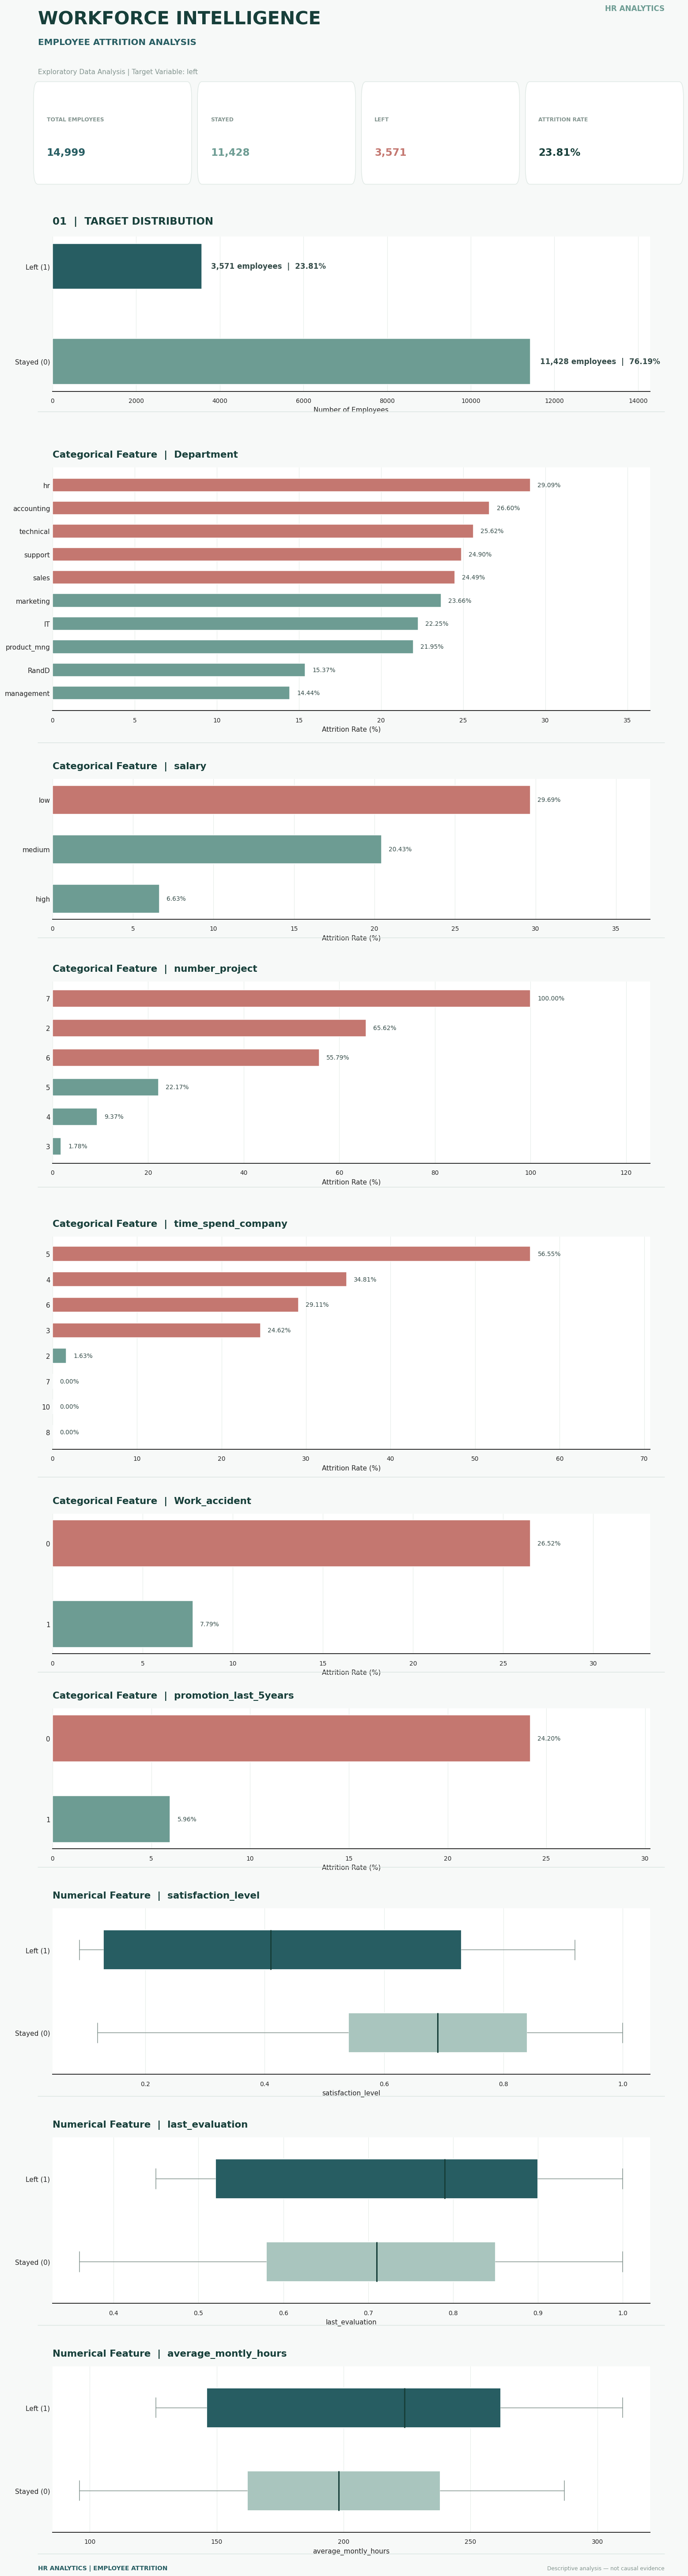

VERTICAL EDA REPORT COMPLETED
Total employees: 14,999
Stayed: 11,428 (76.19%)
Left: 3,571 (23.81%)
Categorical features: 6
Numerical features: 3

Saved image: /content/Employee_Attrition_Vertical_Report.png


In [12]:

# ================================================================
# HR ANALYTICS | EMPLOYEE ATTRITION
# PROFESSIONAL VERTICAL EDA REPORT
# Clean Design | One Long Image | No Reference Lines
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# ================================================================
# 1. LOAD DATA
# ================================================================

FILE_PATH = "/content/HR_capstone_dataset.csv"
TARGET = "left"

df = pd.read_csv(FILE_PATH)

if TARGET not in df.columns:
    raise ValueError("Target column 'left' was not found.")

if df[TARGET].isna().any():
    raise ValueError("Target contains missing values.")

if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("Target must contain only 0 and 1.")

# ================================================================
# 2. DESIGN SETTINGS
# ================================================================

DARK = "#173F3A"
PRIMARY = "#275D62"
TEAL = "#6D9C93"
LIGHT = "#A9C5BE"
BACKGROUND = "#F7F9F8"
WHITE = "#FFFFFF"
TEXT = "#344B48"
MUTED = "#849590"
RED = "#C47770"

OUTPUT_PATH = "/content/Employee_Attrition_Vertical_Report.png"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 10,
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": WHITE,
    "savefig.facecolor": BACKGROUND
})

# ================================================================
# 3. TARGET SUMMARY
# ================================================================

total = len(df)

stayed_count = int((df[TARGET] == 0).sum())
left_count = int((df[TARGET] == 1).sum())

stayed_rate = stayed_count / total * 100
left_rate = left_count / total * 100

# ================================================================
# 4. IDENTIFY FEATURE TYPES
# ================================================================

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col != TARGET
]

# Numeric columns with 10 or fewer unique values
# are treated as categorical.
low_cardinality_cols = [
    col for col in numeric_cols
    if df[col].nunique(dropna=True) <= 10
]

categorical_cols = list(dict.fromkeys(
    categorical_cols + low_cardinality_cols
))

continuous_cols = [
    col for col in numeric_cols
    if col not in low_cardinality_cols
]

# ================================================================
# 5. CATEGORICAL ANALYSIS
# ================================================================

categorical_results = {}

for col in categorical_cols:

    temp = df[[col, TARGET]].dropna()

    summary = (
        temp.groupby(col, observed=True)[TARGET]
        .agg(
            Employees="count",
            Employees_Left="sum",
            Attrition_Rate="mean"
        )
        .reset_index()
    )

    summary["Attrition_Rate"] *= 100

    summary = summary.sort_values(
        "Attrition_Rate",
        ascending=True
    )

    categorical_results[col] = summary

# ================================================================
# 6. NUMERICAL ANALYSIS
# ================================================================

numerical_results = {}

for col in continuous_cols:

    stayed_values = df.loc[
        df[TARGET] == 0, col
    ].dropna()

    left_values = df.loc[
        df[TARGET] == 1, col
    ].dropna()

    numerical_results[col] = {
        "Stayed": stayed_values,
        "Left": left_values
    }

# ================================================================
# 7. CALCULATE DYNAMIC FIGURE HEIGHT
# ================================================================

total_height = 12

# Categorical section heights
for col, summary in categorical_results.items():
    total_height += max(
        3.8,
        2.4 + len(summary) * 0.42
    )

# Numerical section heights
for col in continuous_cols:
    total_height += 4.5

# ================================================================
# 8. CREATE FIGURE
# ================================================================

fig = plt.figure(
    figsize=(15, total_height),
    facecolor=BACKGROUND
)

# ================================================================
# 9. HEADER
# ================================================================

fig.text(
    0.07, 0.985,
    "WORKFORCE INTELLIGENCE",
    fontsize=27,
    fontweight="bold",
    color=DARK,
    ha="left",
    va="top"
)

fig.text(
    0.07, 0.972,
    "EMPLOYEE ATTRITION ANALYSIS",
    fontsize=13,
    fontweight="bold",
    color=PRIMARY,
    ha="left"
)

fig.text(
    0.93, 0.985,
    "HR ANALYTICS",
    fontsize=11,
    fontweight="bold",
    color=TEAL,
    ha="right"
)

fig.text(
    0.07, 0.961,
    "Exploratory Data Analysis | Target Variable: left",
    fontsize=10,
    color=MUTED,
    ha="left"
)

# ================================================================
# 10. KPI CARDS
# ================================================================

kpis = [
    ("TOTAL EMPLOYEES", f"{total:,}", PRIMARY),
    ("STAYED", f"{stayed_count:,}", TEAL),
    ("LEFT", f"{left_count:,}", RED),
    ("ATTRITION RATE", f"{left_rate:.2f}%", DARK)
]

for i, (label, value, color) in enumerate(kpis):

    x = 0.07 + i * 0.225

    card = FancyBboxPatch(
        (x, 0.925),
        0.205,
        0.027,
        boxstyle="round,pad=0.006,rounding_size=0.006",
        transform=fig.transFigure,
        facecolor=WHITE,
        edgecolor="#E0E9E5",
        linewidth=1
    )

    fig.patches.append(card)

    fig.text(
        x + 0.012, 0.943,
        label,
        fontsize=8,
        fontweight="bold",
        color=MUTED
    )

    fig.text(
        x + 0.012, 0.930,
        value,
        fontsize=15,
        fontweight="bold",
        color=color
    )

# ================================================================
# 11. BUILD SECTION LIST
# ================================================================

chart_specs = [
    {
        "type": "target",
        "height": 4.2
    }
]

for col, summary in categorical_results.items():

    chart_specs.append({
        "type": "categorical",
        "column": col,
        "height": max(
            3.8,
            2.4 + len(summary) * 0.42
        )
    })

for col in continuous_cols:

    chart_specs.append({
        "type": "numerical",
        "column": col,
        "height": 4.5
    })

# ================================================================
# 12. DRAW SECTIONS
# ================================================================

current_top = 0.91

for spec in chart_specs:

    height = spec["height"]
    figure_height = height / total_height

    current_bottom = current_top - figure_height

    ax = fig.add_axes([
        0.09,
        current_bottom + 0.10 * figure_height,
        0.82,
        figure_height * 0.76
    ])

    ax.set_facecolor(WHITE)

    # ------------------------------------------------------------
    # A. TARGET DISTRIBUTION
    # ------------------------------------------------------------

    if spec["type"] == "target":

        ax.set_title(
            "01  |  TARGET DISTRIBUTION",
            loc="left",
            color=DARK,
            fontsize=15,
            pad=18
        )

        bars = ax.barh(
            ["Stayed (0)", "Left (1)"],
            [stayed_count, left_count],
            color=[TEAL, PRIMARY],
            height=0.48
        )

        ax.set_xlim(
            0,
            max(stayed_count, left_count) * 1.25
        )

        for bar, percentage in zip(
            bars,
            [stayed_rate, left_rate]
        ):

            value = int(bar.get_width())

            ax.text(
                value + total * 0.015,
                bar.get_y() + bar.get_height() / 2,
                f"{value:,} employees  |  {percentage:.2f}%",
                va="center",
                fontsize=11,
                fontweight="bold",
                color=TEXT
            )

        ax.set_xlabel("Number of Employees")
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.tick_params(axis="y", length=0)

    # ------------------------------------------------------------
    # B. CATEGORICAL FEATURES
    # ------------------------------------------------------------

    elif spec["type"] == "categorical":

        col = spec["column"]
        summary = categorical_results[col]

        labels = summary[col].astype(str).tolist()
        rates = summary["Attrition_Rate"].values

        ax.set_title(
            f"Categorical Feature  |  {col}",
            loc="left",
            color=DARK,
            fontsize=14,
            pad=15
        )

        y = np.arange(len(summary))

        bars = ax.barh(
            y,
            rates,
            color=[
                RED if value > left_rate else TEAL
                for value in rates
            ],
            height=0.58
        )

        ax.set_yticks(y)
        ax.set_yticklabels(labels)

        max_rate = max(
            float(np.max(rates)) if len(rates) else 0,
            1
        )

        ax.set_xlim(0, max_rate * 1.25)

        for bar, rate in zip(bars, rates):

            ax.text(
                rate + max_rate * 0.015,
                bar.get_y() + bar.get_height() / 2,
                f"{rate:.2f}%",
                va="center",
                fontsize=9,
                color=TEXT
            )

        ax.set_xlabel("Attrition Rate (%)")

        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.tick_params(axis="y", length=0)

    # ------------------------------------------------------------
    # C. NUMERICAL FEATURES
    # ------------------------------------------------------------

    elif spec["type"] == "numerical":

        col = spec["column"]

        stayed_values = numerical_results[col]["Stayed"]
        left_values = numerical_results[col]["Left"]

        ax.set_title(
            f"Numerical Feature  |  {col}",
            loc="left",
            color=DARK,
            fontsize=14,
            pad=15
        )

        data = [
            stayed_values.values,
            left_values.values
        ]

        box = ax.boxplot(
            data,
            vert=False,
            patch_artist=True,
            labels=["Stayed (0)", "Left (1)"],
            widths=0.48,
            showfliers=False,
            medianprops={
                "color": DARK,
                "linewidth": 2
            },
            whiskerprops={
                "color": MUTED
            },
            capprops={
                "color": MUTED
            },
            boxprops={
                "edgecolor": WHITE,
                "linewidth": 1.2
            }
        )

        box["boxes"][0].set_facecolor(LIGHT)
        box["boxes"][1].set_facecolor(PRIMARY)

        ax.set_xlabel(col)

        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.tick_params(axis="y", length=0)

    # ------------------------------------------------------------
    # COMMON FORMATTING
    # ------------------------------------------------------------

    ax.grid(
        axis="x",
        color="#E8EEEB",
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    # Horizontal divider between sections
    fig.add_artist(
        plt.Line2D(
            [0.07, 0.93],
            [current_bottom, current_bottom],
            transform=fig.transFigure,
            color="#DCE6E2",
            linewidth=1
        )
    )

    current_top = current_bottom - 0.004

# ================================================================
# 13. FOOTER
# ================================================================

fig.text(
    0.07, 0.012,
    "HR ANALYTICS | EMPLOYEE ATTRITION",
    fontsize=9,
    fontweight="bold",
    color=PRIMARY
)

fig.text(
    0.93, 0.012,
    "Descriptive analysis — not causal evidence",
    fontsize=8,
    color=MUTED,
    ha="right"
)

# ================================================================
# 14. SAVE REPORT
# ================================================================

plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor=BACKGROUND
)

plt.show()
plt.close()

# ================================================================
# 15. FINAL OUTPUT
# ================================================================

print("=" * 60)
print("VERTICAL EDA REPORT COMPLETED")
print("=" * 60)

print(f"Total employees: {total:,}")
print(f"Stayed: {stayed_count:,} ({stayed_rate:.2f}%)")
print(f"Left: {left_count:,} ({left_rate:.2f}%)")

print(f"Categorical features: {len(categorical_cols)}")
print(f"Numerical features: {len(continuous_cols)}")

print(f"\nSaved image: {OUTPUT_PATH}")


##Preprocessing

**Data Quality Assessment & Exploratory Checks**

In [14]:

# ============================================================
# DATA CLEANING
# HR Employee Attrition Prediction
# ============================================================

import pandas as pd
import numpy as np

# Helper function to print section titles
def print_section(title):
    print("\n" + "=" * 65)
    print(f" {title}")
    print("=" * 65)


# ------------------------------------------------------------
# 1. MISSING VALUES
# ------------------------------------------------------------

print_section("1. MISSING VALUES ANALYSIS")

missing_count = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage
})

print(missing_summary)

total_missing = df.isnull().sum().sum()

print(f"\nTotal Missing Values: {total_missing}")

if total_missing == 0:
    print("Result: No missing values found.")
else:
    print("Result: Missing values detected. Further investigation is required.")


# ------------------------------------------------------------
# 2. DUPLICATE VALUES
# ------------------------------------------------------------

print_section("2. DUPLICATE VALUES ANALYSIS")

# Exact duplicate rows
exact_duplicates = df.duplicated().sum()

print(f"Total Exact Duplicate Rows: {exact_duplicates}")
print(f"Duplicate Percentage: {(exact_duplicates / len(df)) * 100:.2f}%")

# Duplicate profiles excluding the target column
features_without_target = df.drop(columns=["left"])

duplicate_profiles = features_without_target.duplicated().sum()

print(f"\nDuplicate Profiles (Excluding Target): {duplicate_profiles}")

# Check whether identical feature profiles have conflicting targets
target_variation = (
    df.groupby(list(features_without_target.columns), dropna=False)["left"]
      .nunique()
)

conflicting_profiles = (target_variation > 1).sum()

print(f"Profiles with Conflicting Target Values: {conflicting_profiles}")

# Target distribution among exact duplicate rows
duplicate_rows = df[df.duplicated(keep=False)]

if not duplicate_rows.empty:
    print("\nTarget Distribution Within Duplicate Rows:")
    print(duplicate_rows["left"].value_counts().sort_index())
else:
    print("\nNo duplicate rows to investigate.")

# Display a sample of duplicate rows
if exact_duplicates > 0:
    print("\nSample Duplicate Rows:")
    display(df[df.duplicated(keep=False)].head(10))


# ------------------------------------------------------------
# 3. OUTLIER DETECTION (IQR METHOD)
# ------------------------------------------------------------

print_section("3. OUTLIER DETECTION - IQR METHOD")

numerical_features = [
    "satisfaction_level",
    "last_evaluation",
    "number_project",
    "average_montly_hours",
    "time_spend_company"
]

outlier_results = []

for column in numerical_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    outlier_count = outlier_mask.sum()
    outlier_percentage = (outlier_count / len(df)) * 100

    outlier_results.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage (%)": outlier_percentage
    })

outlier_summary = pd.DataFrame(outlier_results)

print(outlier_summary.round(3).to_string(index=False))


# ------------------------------------------------------------
# 4. DATA TYPES VALIDATION
# ------------------------------------------------------------

print_section("4. DATA TYPES VALIDATION")

data_types_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Unique Values": df.nunique(),
    "Sample Values": [
        df[column].dropna().unique()[:5].tolist()
        for column in df.columns
    ]
})

print(data_types_summary.to_string())


# Check binary columns
binary_columns = [
    "Work_accident",
    "left",
    "promotion_last_5years"
]

print("\nBinary Columns Validation:")

for column in binary_columns:

    unique_values = set(df[column].dropna().unique())

    is_valid = unique_values.issubset({0, 1})

    print(
        f"{column}: "
        f"{'Valid (0/1)' if is_valid else 'Invalid Values Found'}"
    )

    if not is_valid:
        print("Unexpected Values:", unique_values - {0, 1})


# Check numerical ranges
print("\nNumerical Range Validation:")

range_checks = {
    "satisfaction_level": (0, 1),
    "last_evaluation": (0, 1),
    "number_project": (1, None),
    "average_montly_hours": (0, None),
    "time_spend_company": (0, None)
}

for column, (minimum, maximum) in range_checks.items():

    invalid_mask = pd.Series(False, index=df.index)

    if minimum is not None:
        invalid_mask |= df[column] < minimum

    if maximum is not None:
        invalid_mask |= df[column] > maximum

    invalid_count = invalid_mask.sum()

    print(
        f"{column}: "
        f"{invalid_count} invalid values"
    )


# Check categorical values
print("\nCategorical Features Validation:")

categorical_columns = ["Department", "salary"]

for column in categorical_columns:

    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


# ------------------------------------------------------------
# 5. CLASS IMBALANCE ANALYSIS
# ------------------------------------------------------------

print_section("5. CLASS IMBALANCE ANALYSIS")

target_counts = df["left"].value_counts().sort_index()

target_percentages = (
    df["left"].value_counts(normalize=True).sort_index() * 100
)

class_summary = pd.DataFrame({
    "Class": ["Stayed (0)", "Left (1)"],
    "Count": [
        target_counts.get(0, 0),
        target_counts.get(1, 0)
    ],
    "Percentage (%)": [
        target_percentages.get(0, 0),
        target_percentages.get(1, 0)
    ]
})

print(class_summary.to_string(index=False))

majority_class = target_counts.max()
minority_class = target_counts.min()

imbalance_ratio = majority_class / minority_class

print(f"\nImbalance Ratio: {imbalance_ratio:.2f}:1")

print("\nClass Imbalance Assessment:")

if imbalance_ratio < 1.5:
    print("The dataset is relatively balanced.")
elif imbalance_ratio < 3:
    print("The dataset has moderate class imbalance.")
else:
    print("The dataset has considerable class imbalance.")


# ------------------------------------------------------------
# 6. DATA CLEANING SUMMARY
# ------------------------------------------------------------

print_section("6. DATA CLEANING SUMMARY")

print(f"Dataset Shape: {df.shape}")
print(f"Total Missing Values: {total_missing}")
print(f"Exact Duplicate Rows: {exact_duplicates}")
print(f"Duplicate Profiles: {duplicate_profiles}")
print(f"Conflicting Target Profiles: {conflicting_profiles}")

print("\nData Cleaning Diagnostic Completed.")
print("No rows or columns have been deleted or modified.")



 1. MISSING VALUES ANALYSIS
                       Missing Count  Missing Percentage (%)
satisfaction_level                 0                     0.0
last_evaluation                    0                     0.0
number_project                     0                     0.0
average_montly_hours               0                     0.0
time_spend_company                 0                     0.0
Work_accident                      0                     0.0
left                               0                     0.0
promotion_last_5years              0                     0.0
Department                         0                     0.0
salary                             0                     0.0

Total Missing Values: 0
Result: No missing values found.

 2. DUPLICATE VALUES ANALYSIS
Total Exact Duplicate Rows: 3008
Duplicate Percentage: 20.05%

Duplicate Profiles (Excluding Target): 3008
Profiles with Conflicting Target Values: 0

Target Distribution Within Duplicate Rows:
left
0    2856
1 

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
5,0.41,0.50,2,153,3,0,1,0,sales,low
6,0.10,0.77,6,247,4,0,1,0,sales,low
7,0.92,0.85,5,259,5,0,1,0,sales,low
8,0.89,1.00,5,224,5,0,1,0,sales,low
9,0.42,0.53,2,142,3,0,1,0,sales,low



 3. OUTLIER DETECTION - IQR METHOD
             Feature     Q1     Q3   IQR  Lower Bound  Upper Bound  Outlier Count  Outlier Percentage (%)
  satisfaction_level   0.44   0.82  0.38       -0.130        1.390              0                   0.000
     last_evaluation   0.56   0.87  0.31        0.095        1.335              0                   0.000
      number_project   3.00   5.00  2.00        0.000        8.000              0                   0.000
average_montly_hours 156.00 245.00 89.00       22.500      378.500              0                   0.000
  time_spend_company   3.00   4.00  1.00        1.500        5.500           1282                   8.547

 4. DATA TYPES VALIDATION
                      Data Type  Unique Values                                Sample Values
satisfaction_level      float64             92                [0.38, 0.8, 0.11, 0.72, 0.37]
last_evaluation         float64             65               [0.53, 0.86, 0.88, 0.87, 0.52]
number_project           

**Data Transformation & Preprocessing**

In [15]:

# ============================================================
# 4. DATA TRANSFORMATION
# Categorical Encoding & Feature Scaling
# ============================================================

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler
)
from sklearn.pipeline import Pipeline

# ------------------------------------------------------------
# 1. SEPARATE FEATURES AND TARGET
# ------------------------------------------------------------

print("=" * 60)
print("1. SEPARATING FEATURES AND TARGET")
print("=" * 60)

X = df.drop(columns=["left"])
y = df["left"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


# ------------------------------------------------------------
# 2. IDENTIFY COLUMN TYPES AUTOMATICALLY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("2. AUTOMATIC COLUMN TYPE DETECTION")
print("=" * 60)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# salary is ordinal, while other categorical columns are nominal
ordinal_features = ["salary"]

nominal_features = [
    column for column in categorical_features
    if column not in ordinal_features
]

print("Numeric Features:", numeric_features)
print("Nominal Features:", nominal_features)
print("Ordinal Features:", ordinal_features)


# ------------------------------------------------------------
# 3. CATEGORICAL ENCODING
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("3. CATEGORICAL ENCODING")
print("=" * 60)

nominal_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

ordinal_transformer = OrdinalEncoder(
    categories=[["low", "medium", "high"]],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)


# ------------------------------------------------------------
# 4. FEATURE SCALING
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("4. FEATURE SCALING")
print("=" * 60)

numeric_transformer = StandardScaler()


# ------------------------------------------------------------
# 5. COMBINE TRANSFORMATIONS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("5. BUILDING COLUMN TRANSFORMER")
print("=" * 60)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("nominal", nominal_transformer, nominal_features),
        ("ordinal", ordinal_transformer, ordinal_features)
    ],
    remainder="drop"
)

print("Preprocessor created successfully.")


# ------------------------------------------------------------
# 6. BUILD PREPROCESSING PIPELINE
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("6. BUILDING PREPROCESSING PIPELINE")
print("=" * 60)

transformation_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor)
    ]
)

print("Transformation Pipeline created successfully.")
print("Original DataFrame remains unchanged.")


1. SEPARATING FEATURES AND TARGET
Features Shape: (14999, 9)
Target Shape: (14999,)

2. AUTOMATIC COLUMN TYPE DETECTION
Numeric Features: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'promotion_last_5years']
Nominal Features: ['Department']
Ordinal Features: ['salary']

3. CATEGORICAL ENCODING

4. FEATURE SCALING

5. BUILDING COLUMN TRANSFORMER
Preprocessor created successfully.

6. BUILDING PREPROCESSING PIPELINE
Transformation Pipeline created successfully.
Original DataFrame remains unchanged.


**Data Splitting (Train-Test Split).**

In [16]:
# ============================================================
# 5. DATA SPLITTING
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 60)
print("5. DATA SPLITTING")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

5. DATA SPLITTING
Training Features: (11999, 9)
Testing Features: (3000, 9)

Training Target: (11999,)
Testing Target: (3000,)

Training Target Distribution:
left
0    76.19
1    23.81
Name: proportion, dtype: float64

Testing Target Distribution:
left
0    76.2
1    23.8
Name: proportion, dtype: float64


Aplly Data Transformation

In [18]:

# ============================================================
# 6. DATA TRANSFORMATION
# Encoding & Feature Scaling
# ============================================================

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

print("=" * 60)
print("6. DATA TRANSFORMATION")
print("=" * 60)


# ------------------------------------------------------------
# 1. IDENTIFY FEATURE TYPES
# ------------------------------------------------------------

binary_features = [
    "Work_accident",
    "promotion_last_5years"
]

ordinal_features = ["salary"]

nominal_features = [
    col for col in X_train.select_dtypes(
        include=["object", "category"]
    ).columns
    if col not in ordinal_features
]

continuous_features = [
    col for col in X_train.select_dtypes(
        include=np.number
    ).columns
    if col not in binary_features
]

print("\nContinuous Features:", continuous_features)
print("Binary Features:", binary_features)
print("Nominal Features:", nominal_features)
print("Ordinal Features:", ordinal_features)


# ------------------------------------------------------------
# 2. CREATE TRANSFORMATION PIPELINE
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "scaling",
            StandardScaler(),
            continuous_features
        ),
        (
            "nominal_encoding",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            nominal_features
        ),
        (
            "ordinal_encoding",
            OrdinalEncoder(
                categories=[["low", "medium", "high"]],
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
            ordinal_features
        )
    ],
    remainder="passthrough"
)


# ------------------------------------------------------------
# 3. FIT AND TRANSFORM TRAINING DATA
# ------------------------------------------------------------

X_train_transformed = preprocessor.fit_transform(X_train)


# ------------------------------------------------------------
# 4. TRANSFORM TESTING DATA
# ------------------------------------------------------------

X_test_transformed = preprocessor.transform(X_test)


# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TRANSFORMATION RESULTS")
print("=" * 60)

print("Original Training Shape:", X_train.shape)
print("Transformed Training Shape:", X_train_transformed.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Transformed Testing Shape:", X_test_transformed.shape)

print("\nTraining Transformation: Completed")
print("Testing Transformation: Completed")

print("\nData Transformation Completed Successfully.")


6. DATA TRANSFORMATION

Continuous Features: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company']
Binary Features: ['Work_accident', 'promotion_last_5years']
Nominal Features: ['Department']
Ordinal Features: ['salary']

TRANSFORMATION RESULTS
Original Training Shape: (11999, 9)
Transformed Training Shape: (11999, 18)

Original Testing Shape: (3000, 9)
Transformed Testing Shape: (3000, 18)

Training Transformation: Completed
Testing Transformation: Completed

Data Transformation Completed Successfully.


#Baseline Modeling

In [19]:
#Import Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
#Model Initialization
#Hyperparameters
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

#Model Training
trained_models = {}

for name, model in models.items():

    model.fit(X_train_transformed, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!")



Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


**Prediction**

In [20]:
test_predictions = {}

for name, model in trained_models.items():

    predictions = model.predict(X_test_transformed)

    test_predictions[name] = predictions

    print(f"{name}: Prediction completed!")

Logistic Regression: Prediction completed!
Decision Tree: Prediction completed!
Random Forest: Prediction completed!


**Overfitting Check**

In [21]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

overfitting_results = []

for name, model in trained_models.items():

    # Predictions on Training Data
    train_pred = model.predict(X_train_transformed)

    # Predictions on Testing Data
    test_pred = model.predict(X_test_transformed)

    # Calculate Metrics
    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)

    train_f1 = f1_score(y_train, train_pred)
    test_f1 = f1_score(y_test, test_pred)

    # Store Results
    overfitting_results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Accuracy Gap": train_accuracy - test_accuracy,
        "Train F1": train_f1,
        "Test F1": test_f1,
        "F1 Gap": train_f1 - test_f1
    })

overfitting_df = pd.DataFrame(overfitting_results)

display(overfitting_df.round(4))

,Model,Train Accuracy,Test Accuracy,Accuracy Gap,Train F1,Test F1,F1 Gap
0,Logistic Regression,0.7575,0.7693,-0.0119,0.6107,0.6223,-0.0116
1,Decision Tree,0.9724,0.9647,0.0077,0.9429,0.9269,0.0160
2,Random Forest,0.9823,0.9797,0.0027,0.9619,0.9561,0.0059


In [22]:
# Check duplicate feature profiles across Train and Test

overlapping_profiles = X_train.merge(
    X_test.drop_duplicates(),
    on=list(X.columns),
    how="inner"
)

print("Overlapping Profiles:", len(overlapping_profiles))
print("Unique Overlapping Profiles:",
      len(overlapping_profiles.drop_duplicates()))

Overlapping Profiles: 1160
Unique Overlapping Profiles: 877


In [23]:
# Remove Exact Duplicates

df_clean = df.drop_duplicates().copy()

print("Original Dataset:", df.shape)
print("After Removing Duplicates:", df_clean.shape)
print("Removed Rows:", len(df) - len(df_clean))

Original Dataset: (14999, 10)
After Removing Duplicates: (11991, 10)
Removed Rows: 3008


In [24]:
X = df_clean.drop("left", axis=1)
y = df_clean["left"]

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [26]:
X_train_transformed = preprocessor.fit_transform(X_train)

X_test_transformed = preprocessor.transform(X_test)

In [27]:
#Import Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
#Model Initialization
#Hyperparameters
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

#Model Training
trained_models = {}

for name, model in models.items():

    model.fit(X_train_transformed, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!")



Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [28]:
test_predictions = {}

for name, model in trained_models.items():

    predictions = model.predict(X_test_transformed)

    test_predictions[name] = predictions

    print(f"{name}: Prediction completed!")

Logistic Regression: Prediction completed!
Decision Tree: Prediction completed!
Random Forest: Prediction completed!


In [29]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

overfitting_results = []

for name, model in trained_models.items():

    # Predictions on Training Data
    train_pred = model.predict(X_train_transformed)

    # Predictions on Testing Data
    test_pred = model.predict(X_test_transformed)

    # Calculate Metrics
    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)

    train_f1 = f1_score(y_train, train_pred)
    test_f1 = f1_score(y_test, test_pred)

    # Store Results
    overfitting_results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Accuracy Gap": train_accuracy - test_accuracy,
        "Train F1": train_f1,
        "Test F1": test_f1,
        "F1 Gap": train_f1 - test_f1
    })

overfitting_df = pd.DataFrame(overfitting_results)

display(overfitting_df.round(4))

,Model,Train Accuracy,Test Accuracy,Accuracy Gap,Train F1,Test F1,F1 Gap
0,Logistic Regression,0.7710,0.7816,-0.0106,0.5447,0.5611,-0.0165
1,Decision Tree,0.9713,0.9642,0.0072,0.9166,0.8961,0.0205
2,Random Forest,0.9846,0.9829,0.0017,0.9524,0.9472,0.0051


# Model Evaluation

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

evaluation_results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_transformed)
    y_prob = model.predict_proba(X_test_transformed)[:, 1]

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7816,0.4209,0.8417,0.5611,0.8502
1,Decision Tree,0.9642,0.8628,0.9322,0.8961,0.9704
2,Random Forest,0.9829,0.9710,0.9246,0.9472,0.9821


**Confusion Matrix**

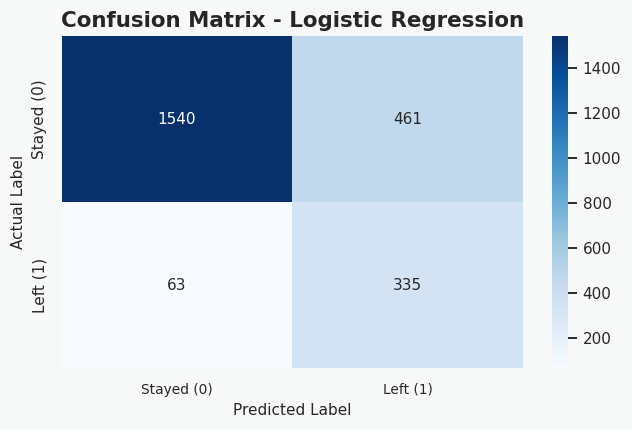

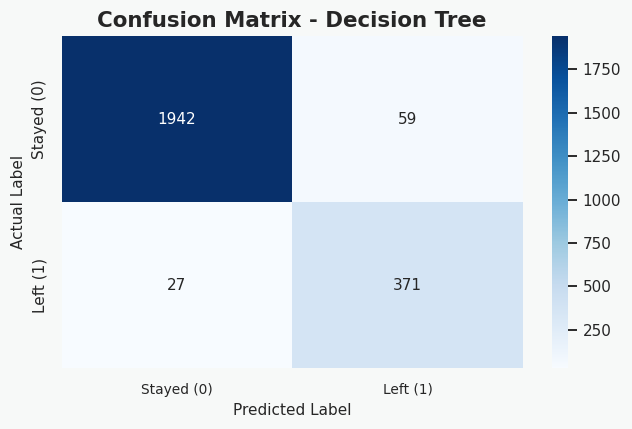

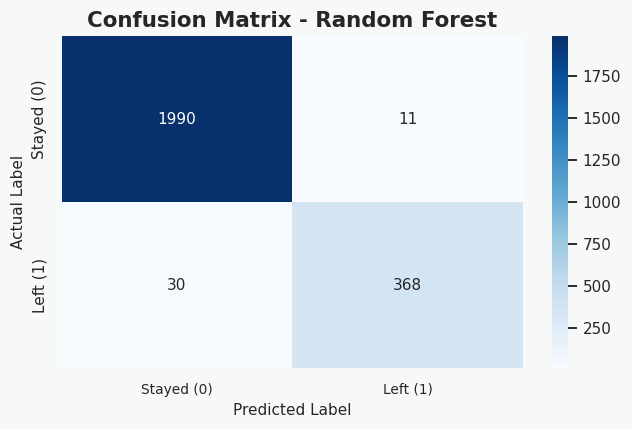

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

for name, model in trained_models.items():

    y_pred = model.predict(X_test_transformed)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stayed (0)", "Left (1)"],
        yticklabels=["Stayed (0)", "Left (1)"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

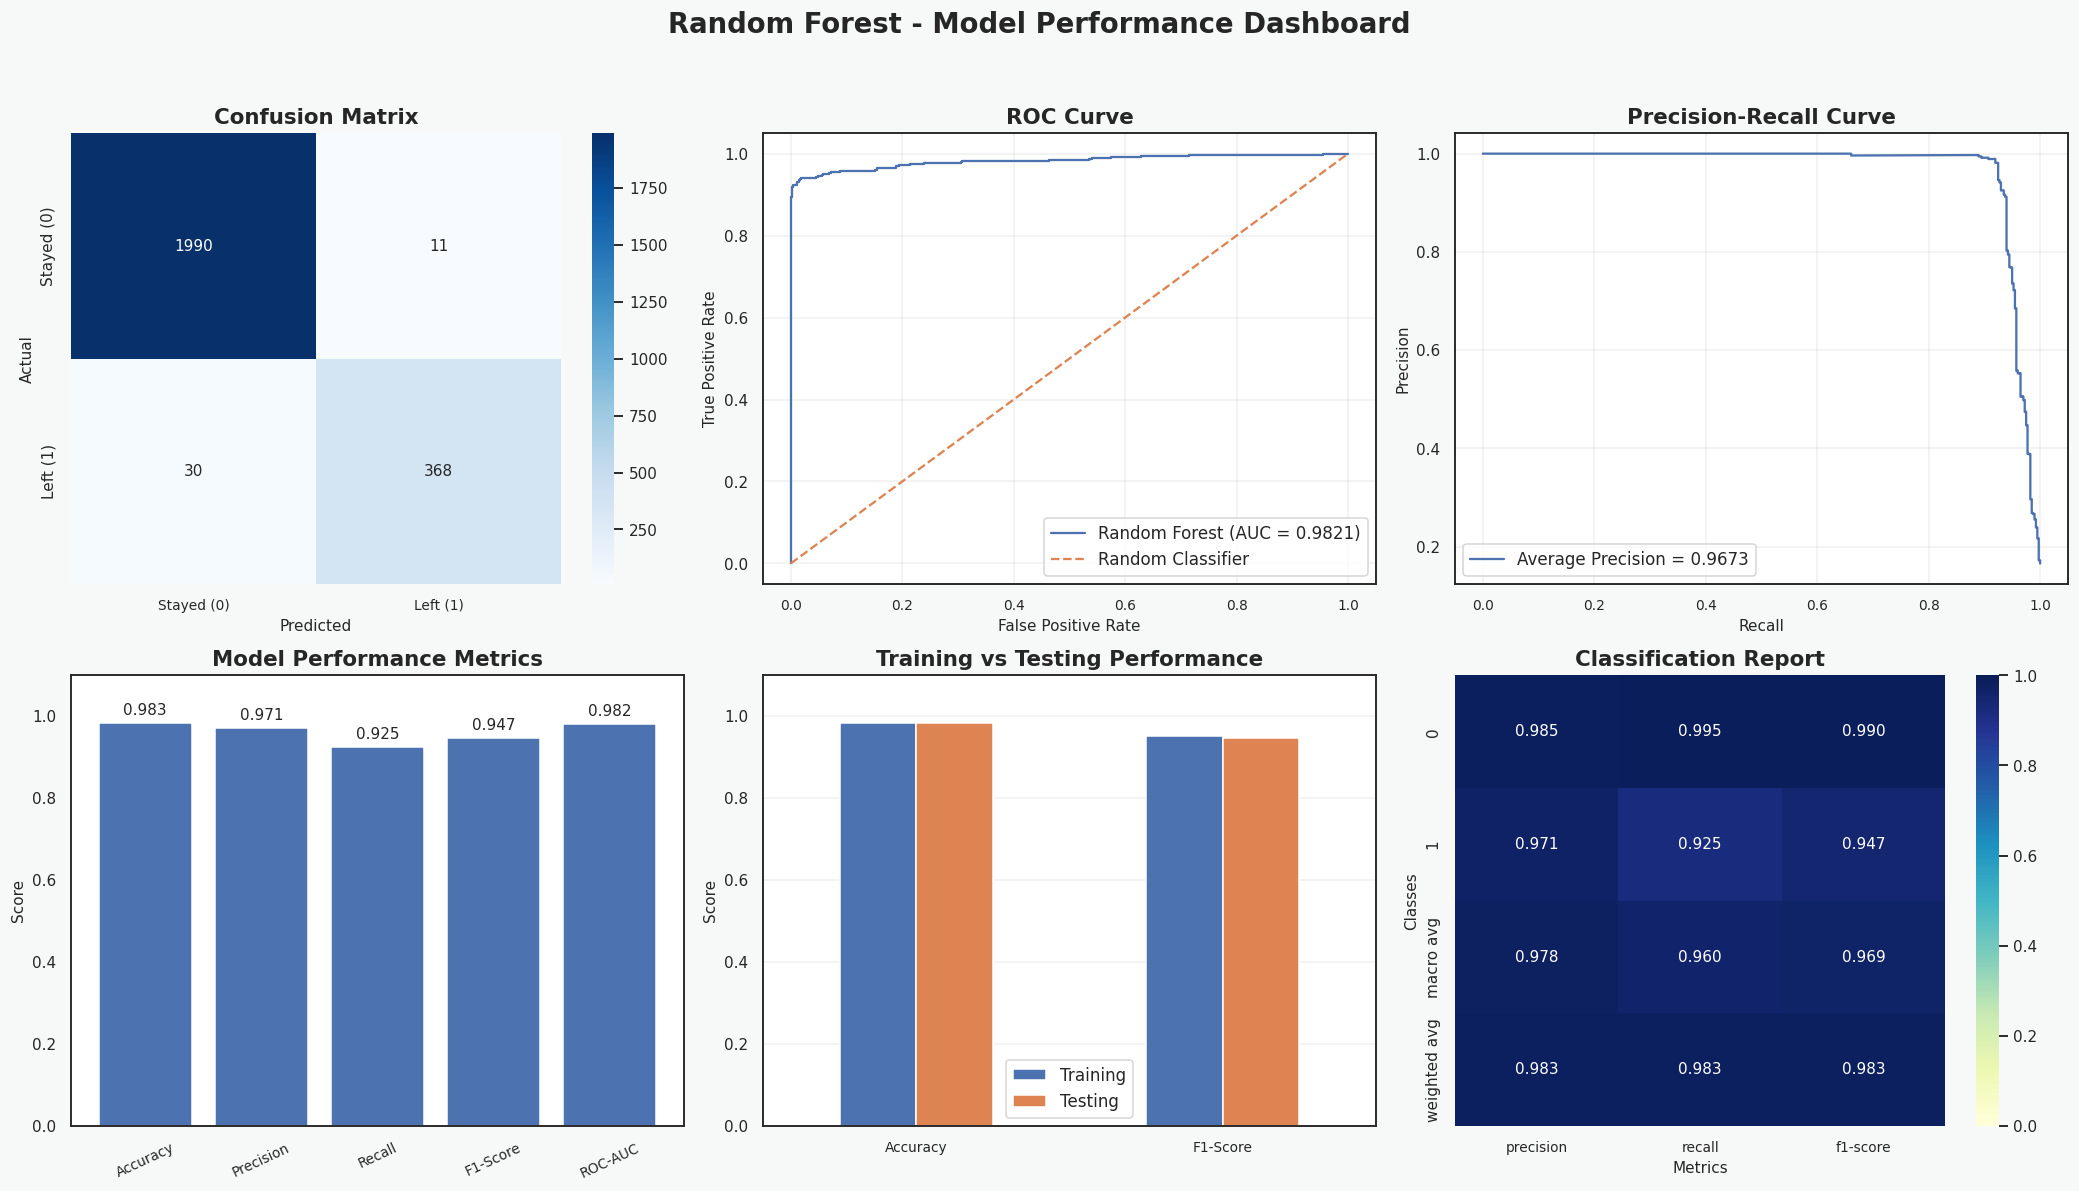


RANDOM FOREST PERFORMANCE SUMMARY
Accuracy: 0.9829
Precision: 0.9710
Recall: 0.9246
F1-Score: 0.9472
ROC-AUC: 0.9821


In [32]:

# ============================================================
# RANDOM FOREST - MODEL PERFORMANCE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Select Best Model
best_model = trained_models["Random Forest"]

# 2. Generate Predictions
y_pred = best_model.predict(X_test_transformed)
y_prob = best_model.predict_proba(X_test_transformed)[:, 1]

# 3. Calculate Performance Metrics
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred),
    "ROC-AUC": auc(*roc_curve(y_test, y_prob)[:2])
}

# 4. Training Predictions
train_pred = best_model.predict(X_train_transformed)

train_metrics = {
    "Accuracy": accuracy_score(y_train, train_pred),
    "F1-Score": f1_score(y_train, train_pred)
}

test_metrics = {
    "Accuracy": metrics["Accuracy"],
    "F1-Score": metrics["F1-Score"]
}

# ============================================================
# VISUALIZATION
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

fig.suptitle(
    "Random Forest - Model Performance Dashboard",
    fontsize=18,
    fontweight="bold"
)

# ------------------------------------------------------------
# 1. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed (0)", "Left (1)"],
    yticklabels=["Stayed (0)", "Left (1)"],
    ax=axes[0, 0]
)

axes[0, 0].set_title("Confusion Matrix")
axes[0, 0].set_xlabel("Predicted")
axes[0, 0].set_ylabel("Actual")

# ------------------------------------------------------------
# 2. ROC CURVE
# ------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

axes[0, 1].plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

axes[0, 1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

axes[0, 1].set_title("ROC Curve")
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# ------------------------------------------------------------
# 3. PRECISION-RECALL CURVE
# ------------------------------------------------------------

precision_values, recall_values, _ = precision_recall_curve(
    y_test,
    y_prob
)

avg_precision = average_precision_score(y_test, y_prob)

axes[0, 2].plot(
    recall_values,
    precision_values,
    label=f"Average Precision = {avg_precision:.4f}"
)

axes[0, 2].set_title("Precision-Recall Curve")
axes[0, 2].set_xlabel("Recall")
axes[0, 2].set_ylabel("Precision")
axes[0, 2].legend()
axes[0, 2].grid(alpha=0.3)

# ------------------------------------------------------------
# 4. PERFORMANCE METRICS
# ------------------------------------------------------------

metric_names = list(metrics.keys())
metric_values = list(metrics.values())

bars = axes[1, 0].bar(
    metric_names,
    metric_values
)

axes[1, 0].set_title("Model Performance Metrics")
axes[1, 0].set_ylabel("Score")
axes[1, 0].set_ylim(0, 1.1)
axes[1, 0].tick_params(axis="x", rotation=25)

for bar, value in zip(bars, metric_values):
    axes[1, 0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center"
    )

# ------------------------------------------------------------
# 5. TRAIN VS TEST PERFORMANCE
# ------------------------------------------------------------

comparison_df = pd.DataFrame({
    "Training": train_metrics,
    "Testing": test_metrics
})

comparison_df.plot(
    kind="bar",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Training vs Testing Performance")
axes[1, 1].set_ylabel("Score")
axes[1, 1].set_ylim(0, 1.1)
axes[1, 1].tick_params(axis="x", rotation=0)
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

# ------------------------------------------------------------
# 6. CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

report_df = report_df.loc[
    ["0", "1", "macro avg", "weighted avg"],
    ["precision", "recall", "f1-score"]
]

sns.heatmap(
    report_df,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    ax=axes[1, 2]
)

axes[1, 2].set_title("Classification Report")
axes[1, 2].set_xlabel("Metrics")
axes[1, 2].set_ylabel("Classes")

# ------------------------------------------------------------
# FINAL DISPLAY
# ------------------------------------------------------------

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Print Final Results
print("\nRANDOM FOREST PERFORMANCE SUMMARY")
print("=" * 45)

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}")


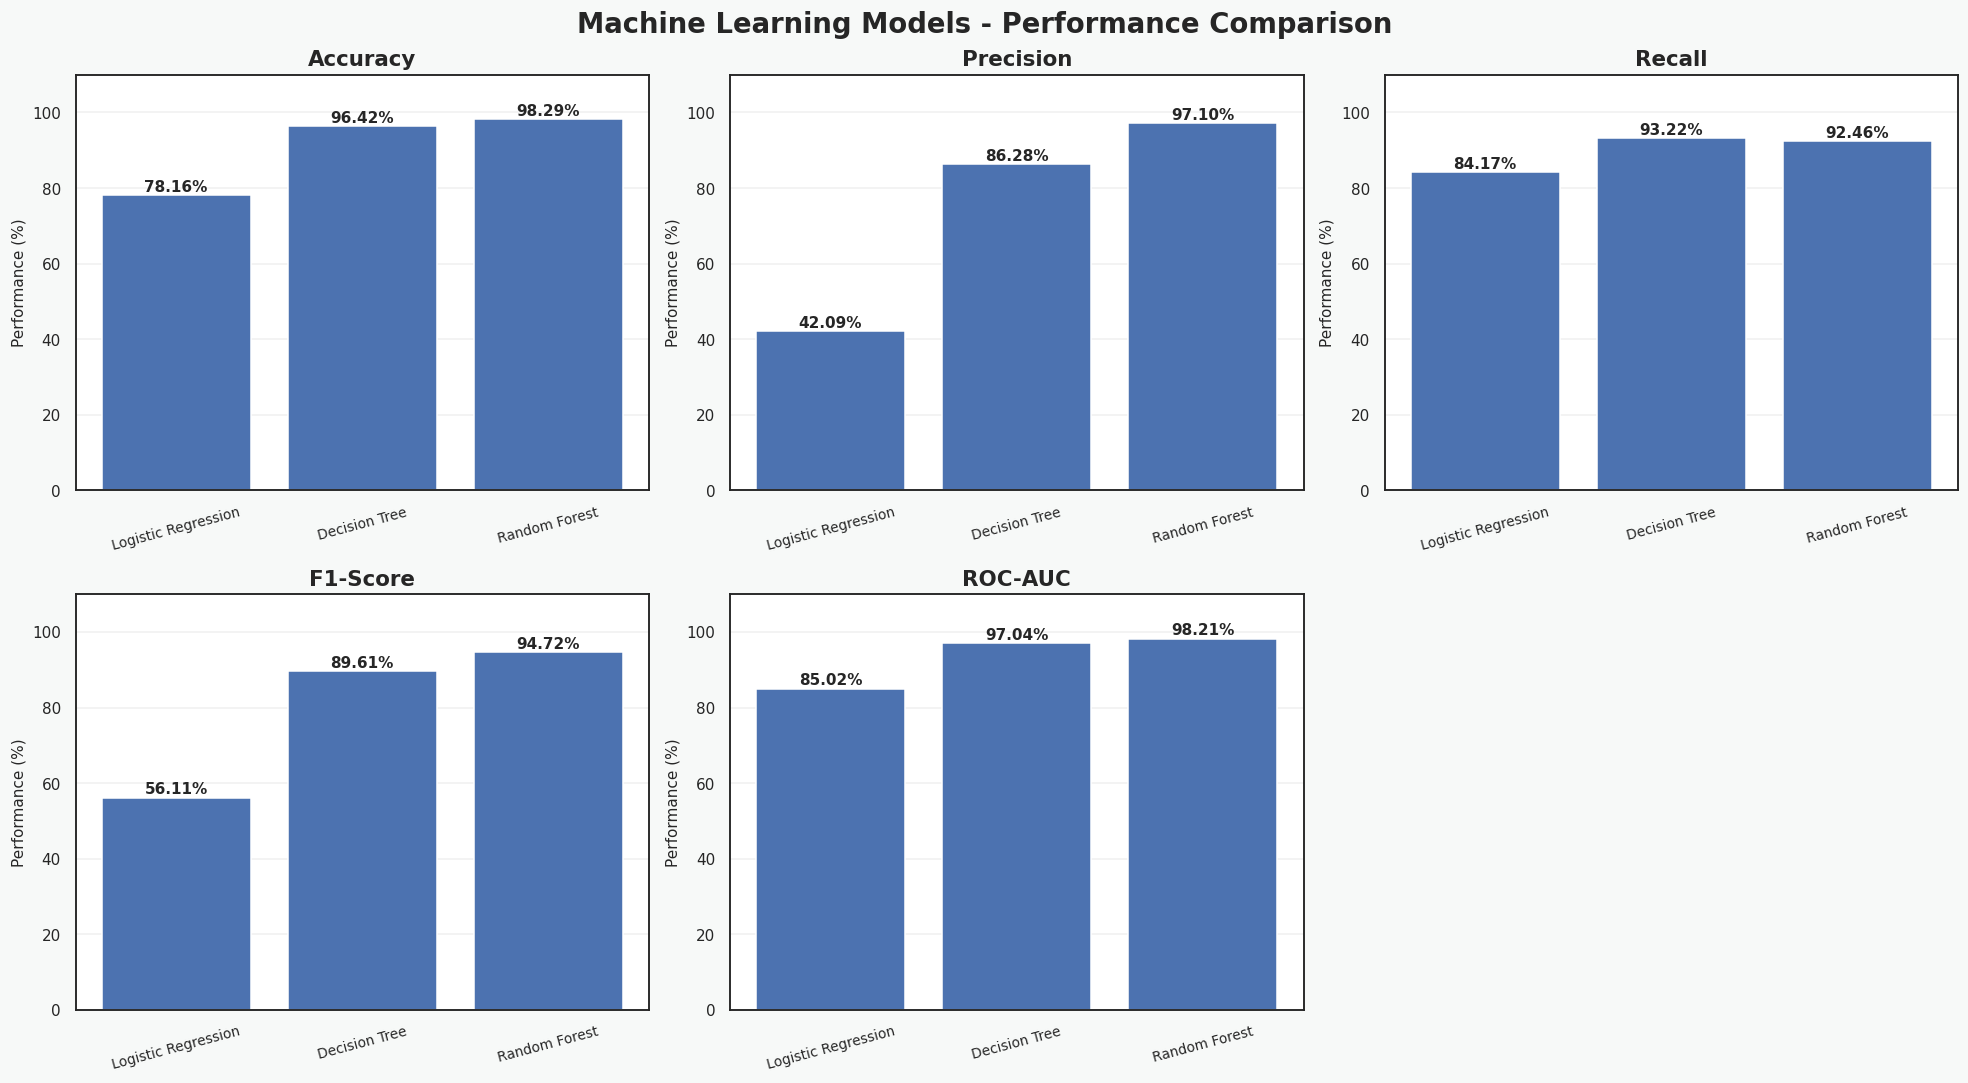

In [33]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Convert evaluation results to percentages
comparison_df = evaluation_df.set_index("Model") * 100

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

# Create 5 comparison charts
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

fig.suptitle(
    "Machine Learning Models - Performance Comparison",
    fontsize=18,
    fontweight="bold"
)

axes = axes.flatten()

for i, metric in enumerate(metrics):

    ax = axes[i]

    values = comparison_df[metric]

    bars = ax.bar(
        values.index,
        values.values
    )

    ax.set_title(metric, fontsize=14, fontweight="bold")
    ax.set_ylabel("Performance (%)")
    ax.set_ylim(0, 110)
    ax.tick_params(axis="x", rotation=15)

    # Display percentage above each bar
    for bar, value in zip(bars, values.values):

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.2f}%",
            ha="center",
            fontweight="bold"
        )

    ax.grid(axis="y", alpha=0.3)

# Remove unused sixth chart
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()


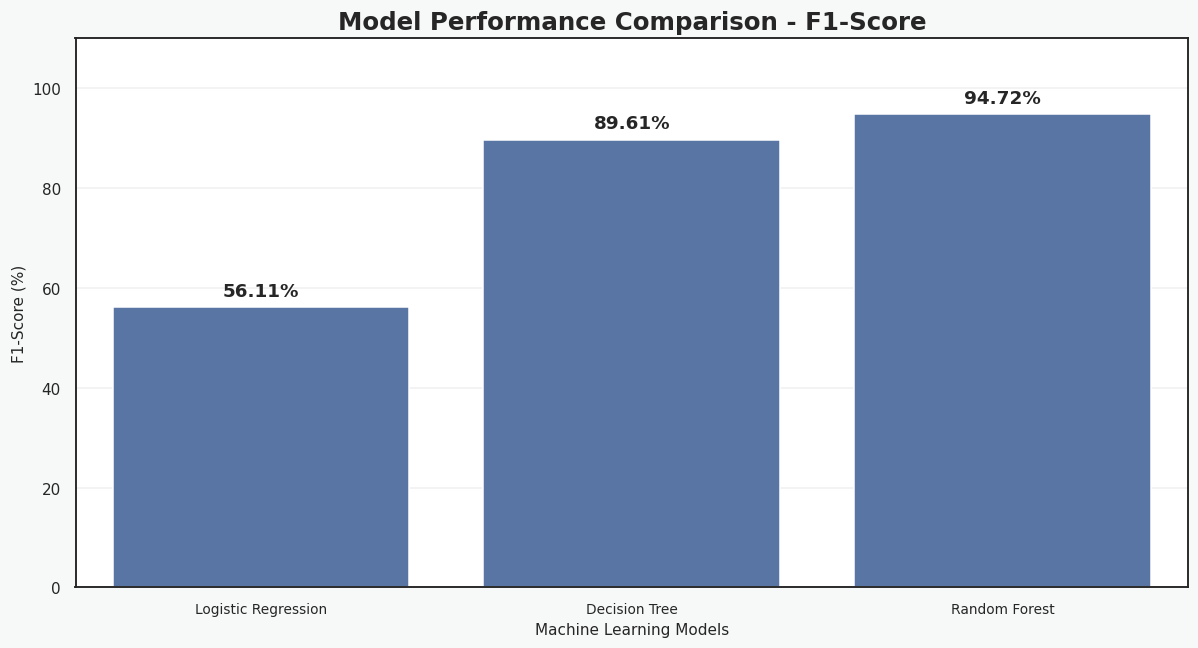

In [35]:

import matplotlib.pyplot as plt
import seaborn as sns

# Convert F1-Score to percentage
plot_df = evaluation_df.copy()
plot_df["F1-Score (%)"] = plot_df["F1-Score"] * 100

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=plot_df,
    x="Model",
    y="F1-Score (%)"
)

# Display percentages
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=5,
        fontweight="bold",
        fontsize=12
    )

plt.title(
    "Model Performance Comparison - F1-Score",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Machine Learning Models")
plt.ylabel("F1-Score (%)")
plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


-------------------------------------------------

-----------------------------------------------------------------------------------------